# SomnIA: resultados del experimento con metaheurísticas y reglas evolutivas

Este notebook analiza los resultados que produjo `SomnIA_metaheuristicas_colab.ipynb` (ejecutado en Colab Pro+, GPU NVIDIA RTX PRO 6000). No entrena nada: lee los CSV de `resultados/`. Las métricas principales son el **F1 de la clase Drowsy** y la **sensibilidad (recall) de Drowsy**, porque en somnolencia lo grave es no detectar a un conductor dormido.

## 1. En qué consistió el experimento

Se probó si las metaheurísticas bioinspiradas encuentran una configuración de hiperparámetros de la red **VGG19 + Attention** mejor que la del paper [1]. Cada evaluación **entrena la red completa** desde ImageNet y la mide en personas que el modelo nunca vio (partición por persona, pliegue 0).

| Elemento | Experimento 1: metaheurísticas | Experimento 2: reglas evolutivas |
|---|---|---|
| **Unidad experimental** | Red VGG19 + Attention completa | Clasificador final de somnolencia |
| **Variables independientes (factores)** | Método de búsqueda, 6 niveles: Paper (control, sin búsqueda), Aleatoria (referencia mínima), **Genético**, **Abejas (ABC)**, **Luciérnagas**, **Murciélagos** | Clasificador (regresión logística, **Michigan**, **Pittsburgh**) × red de entrada (original del paper u optimizada por el Genético) |
| **Variables dependientes (respuestas)** | **F1 de Drowsy** y **sensibilidad de Drowsy** en prueba (principales), sensibilidad de alerta, accuracy y tiempo | **F1 de Drowsy** y **sensibilidad de Drowsy** en prueba, sensibilidad de alerta y número de reglas |
| **Variables controladas (fijas)** | Partición por persona y datos, máximo 4 épocas con paciencia 2, aumento de datos, calibración por persona, clasificador final y **el mismo presupuesto para todos (20 redes por corrida, población de 6)** | Mismas características $[z_L, z_R, \text{cierre}_L, \text{cierre}_R]$ y la misma partición |
| **Variables no controladas** | Calidad de las etiquetas de MediaPipe y GPU asignada por Colab | Ídem |
| **Función de ajuste (aptitud)** | Accuracy de somnolencia en **validación** (5 personas que no están en entrenamiento ni en prueba). La prueba solo se mide al final, con la mejor configuración de cada corrida. | Michigan: precisión de cada regla elevada a ν = 5. Pittsburgh: accuracy balanceada del conjunto de reglas − 0,002 × número de reglas. |
| **Cantidad de ejecuciones** | 6 métodos × **3 repeticiones** (semillas) = 18 corridas; 20 evaluaciones por corrida → **303 evaluaciones = 228 redes distintas entrenadas** (~2,5 h de GPU); las configuraciones repetidas, como la población inicial que comparten los algoritmos en cada repetición, se reutilizan de la caché | 3 × 2 × **3 repeticiones** = 18 ejecuciones |
| **Análisis** | ANOVA de un factor, Tukey HSD y t de Welch frente al control | ANOVA de dos factores con interacción |

**Hiperparámetros que ajusta cada metaheurística** (8 genes en [0, 1]):

| Hiperparámetro | Rango | Paper |
|---|---|---|
| Tasa de aprendizaje | 1e-5 a 3e-3 | 1e-4 |
| Neuronas de la capa 1 del MLP | 32 a 1024 | 512 |
| Neuronas de la capa 2 | 25 % a 100 % de la capa 1 | 256 |
| Dropout | 0 a 0,7 | 0,5 |
| Neuronas del cuello de la atención | 4 a 128 | 32 |
| Weight decay | 1e-6 a 1e-2 | 0 |
| Convoluciones congeladas de la VGG19 | 0 a 16 | 10 |
| Tamaño de lote | 32, 64, 128 | 64 |

**Cómo busca cada metaheurística:**
- **Genético:** selección por torneo, cruce BLX-α, mutación gaussiana y elitismo.
- **Abejas (ABC):** obreras, observadoras y exploradoras.
- **Luciérnagas:** cada luciérnaga vuela hacia las más brillantes, con una atracción que disminuye con la distancia.
- **Murciélagos:** ecolocalización con frecuencia, velocidad, volumen y tasa de pulsos.

**Reglas evolutivas:**
- **Michigan:** cada individuo es *una regla* y la población entera es el clasificador.
- **Pittsburgh:** cada individuo es *un conjunto completo de reglas*.

In [1]:
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import statsmodels.api as sm
from statsmodels.formula.api import ols
from statsmodels.stats.multicomp import pairwise_tukeyhsd
from scipy import stats
from IPython.display import Image, display
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
R = next(p for p in [Path("/content/drive/MyDrive/SomnIA_colab/resultados"), Path.cwd() / "resultados", Path.cwd() / "colab_metaheuristicas/resultados"]
         if p.exists())   # en Colab: monta Drive primero (from google.colab import drive; drive.mount("/content/drive"))
E1, E2, H1 = pd.read_csv(R / "experimento1.csv"), pd.read_csv(R / "experimento2.csv"), pd.read_csv(R / "historial1.csv")
ORDEN = ["Paper (sin búsqueda)", "Aleatoria", "Genético", "Abejas (ABC)", "Luciérnagas", "Murciélagos"]
COLORES = dict(zip(ORDEN, ["#7f7f7f", "#bcbd22", "#1f77b4", "#ff7f0e", "#2ca02c", "#9467bd"]))
print(f"Experimento 1: {len(E1)} corridas ({E1.groupby('algoritmo').size().to_dict()}) | {len(H1) + 3} evaluaciones de aptitud")
print(f"Experimento 2: {len(E2)} ejecuciones")

Experimento 1: 18 corridas ({'Abejas (ABC)': 3, 'Aleatoria': 3, 'Genético': 3, 'Luciérnagas': 3, 'Murciélagos': 3, 'Paper (sin búsqueda)': 3}) | 303 evaluaciones de aptitud
Experimento 2: 18 ejecuciones


## 2. Resultados del experimento 1: metaheurísticas
### 2.1 Tabla principal: F1 y sensibilidad de Drowsy en prueba (media ± desviación, 3 repeticiones)

In [2]:
ms = lambda df, c: (df[c].mean() * 100).round(1).astype(str) + " ± " + (df[c].std() * 100).round(1).astype(str)
g = E1.groupby("algoritmo")
T1 = pd.DataFrame({"F1 Drowsy (%)": ms(g, "f1_test"), "Sens. Drowsy (%)": ms(g, "recall_drowsy_test"),
                   "Sens. alerta (%)": ms(g, "recall_alerta_test"), "Accuracy (%)": ms(g, "accuracy_test"),
                   "Aptitud en validación (%)": ms(g, "aptitud_val"),
                   "Δ F1 vs. paper (pts)": ((g["f1_test"].mean() - g["f1_test"].mean()[ORDEN[0]]) * 100).round(1),
                   "Δ Sens. Drowsy vs. paper (pts)": ((g["recall_drowsy_test"].mean() - g["recall_drowsy_test"].mean()[ORDEN[0]]) * 100).round(1)}).reindex(ORDEN)
T1.to_csv(R / "tabla_drowsy_experimento1.csv"); T1

,F1 Drowsy (%),Sens. Drowsy (%),Sens. alerta (%),Accuracy (%),Aptitud en validación (%),Δ F1 vs. paper (pts),Δ Sens. Drowsy vs. paper (pts)
algoritmo,,,,,,,
Paper (sin búsqueda),72.8 ± 0.6,80.8 ± 0.7,58.9 ± 2.0,69.8 ± 0.9,75.1 ± 1.5,0.0,0.0
Aleatoria,66.8 ± 9.4,74.9 ± 20.1,53.3 ± 14.0,64.1 ± 5.1,82.4 ± 2.6,-6.0,-5.8
Genético,76.2 ± 2.7,86.7 ± 1.5,58.7 ± 10.7,72.7 ± 4.6,84.4 ± 3.8,3.3,5.9
Abejas (ABC),72.4 ± 0.6,81.9 ± 2.2,55.5 ± 5.6,68.8 ± 1.7,83.7 ± 3.8,-0.4,1.2
Luciérnagas,76.3 ± 0.6,85.2 ± 1.9,61.6 ± 2.6,73.4 ± 0.8,83.9 ± 3.3,3.4,4.5
Murciélagos,74.9 ± 2.7,82.6 ± 4.3,62.0 ± 6.6,72.3 ± 3.3,83.4 ± 1.5,2.1,1.8


In [3]:
print("Resultado de cada corrida (F1 y sensibilidad de Drowsy en prueba):")
E1.pivot_table(index="algoritmo", columns="repeticion", values=["f1_test", "recall_drowsy_test"]).reindex(ORDEN).mul(100).round(1)

Resultado de cada corrida (F1 y sensibilidad de Drowsy en prueba):


f1_test             recall_drowsy_test            
repeticion                 0     1     2                  0     1     2
algoritmo                                                              
Paper (sin búsqueda)    72.4  72.6  73.5               81.3  80.0  81.0
Aleatoria               71.2  73.2  56.0               89.4  83.4  52.0
Genético                77.6  77.9  73.0               86.6  85.3  88.2
Abejas (ABC)            72.9  71.8  72.6               81.2  84.4  80.2
Luciérnagas             75.8  77.0  76.0               83.0  86.1  86.5
Murciélagos             74.2  72.7  77.8               78.1  82.9  86.8

### 2.2 Gráficas

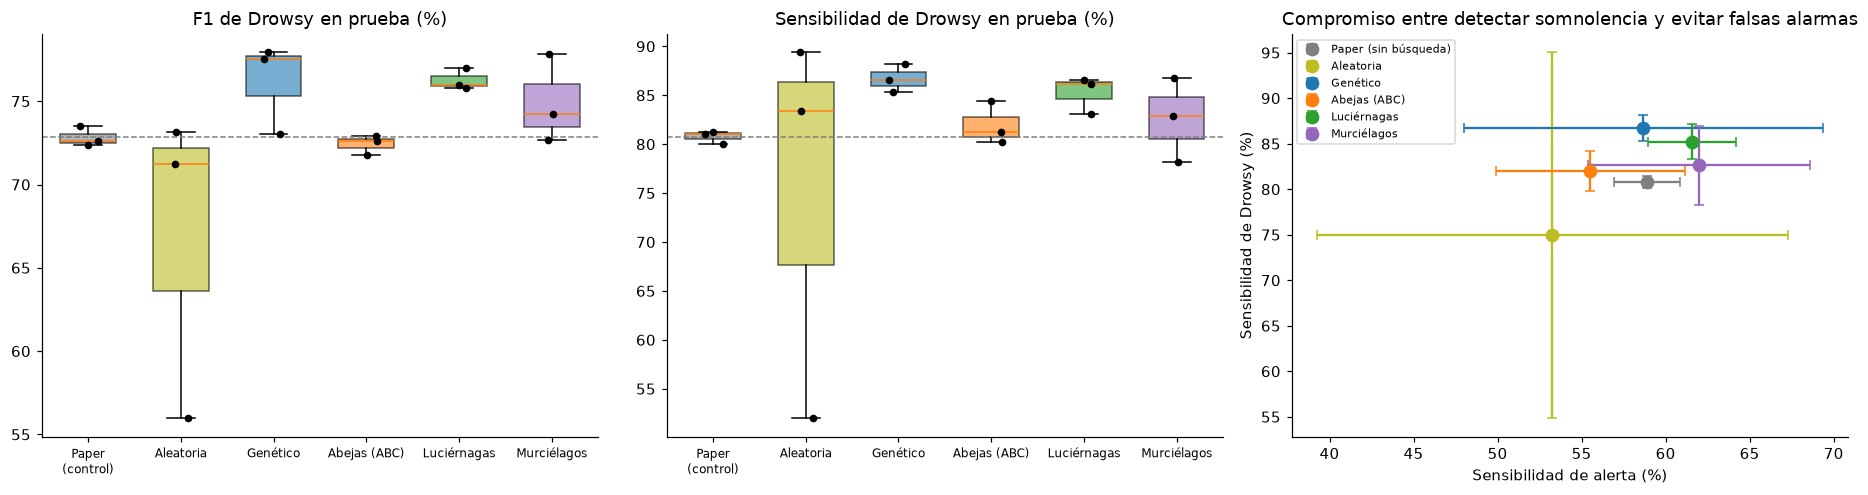

In [4]:
fig, ax = plt.subplots(1, 3, figsize=(17, 4.6))
for k, (col, tit) in enumerate([("f1_test", "F1 de Drowsy en prueba (%)"), ("recall_drowsy_test", "Sensibilidad de Drowsy en prueba (%)")]):
    vals = [E1[E1.algoritmo == a][col] * 100 for a in ORDEN]
    b = ax[k].boxplot(vals, patch_artist=True, widths=0.6)
    for p, a in zip(b["boxes"], ORDEN): p.set_facecolor(COLORES[a]); p.set_alpha(0.6)
    for i, v in enumerate(vals, 1): ax[k].scatter(np.full(len(v), i) + np.random.default_rng(i).uniform(-0.12, 0.12, len(v)), v, s=16, color="k", zorder=3)
    ax[k].axhline(E1[E1.algoritmo == ORDEN[0]][col].mean() * 100, color="gray", ls="--", lw=1)
    ax[k].set_xticks(range(1, 7), [a.replace(" (sin búsqueda)", "\n(control)") for a in ORDEN], fontsize=8); ax[k].set_title(tit)
for a in ORDEN:
    s = E1[E1.algoritmo == a]
    ax[2].errorbar(s["recall_alerta_test"].mean() * 100, s["recall_drowsy_test"].mean() * 100, xerr=s["recall_alerta_test"].std() * 100,
                   yerr=s["recall_drowsy_test"].std() * 100, fmt="o", ms=8, color=COLORES[a], capsize=3, label=a)
ax[2].set(xlabel="Sensibilidad de alerta (%)", ylabel="Sensibilidad de Drowsy (%)", title="Compromiso entre detectar somnolencia y evitar falsas alarmas")
ax[2].legend(fontsize=7)
plt.tight_layout(); plt.savefig(R / "fig_drowsy_experimento1.png", dpi=150); plt.show()

Convergencia de la aptitud (validación) y distribución de la accuracy, generadas en Colab:


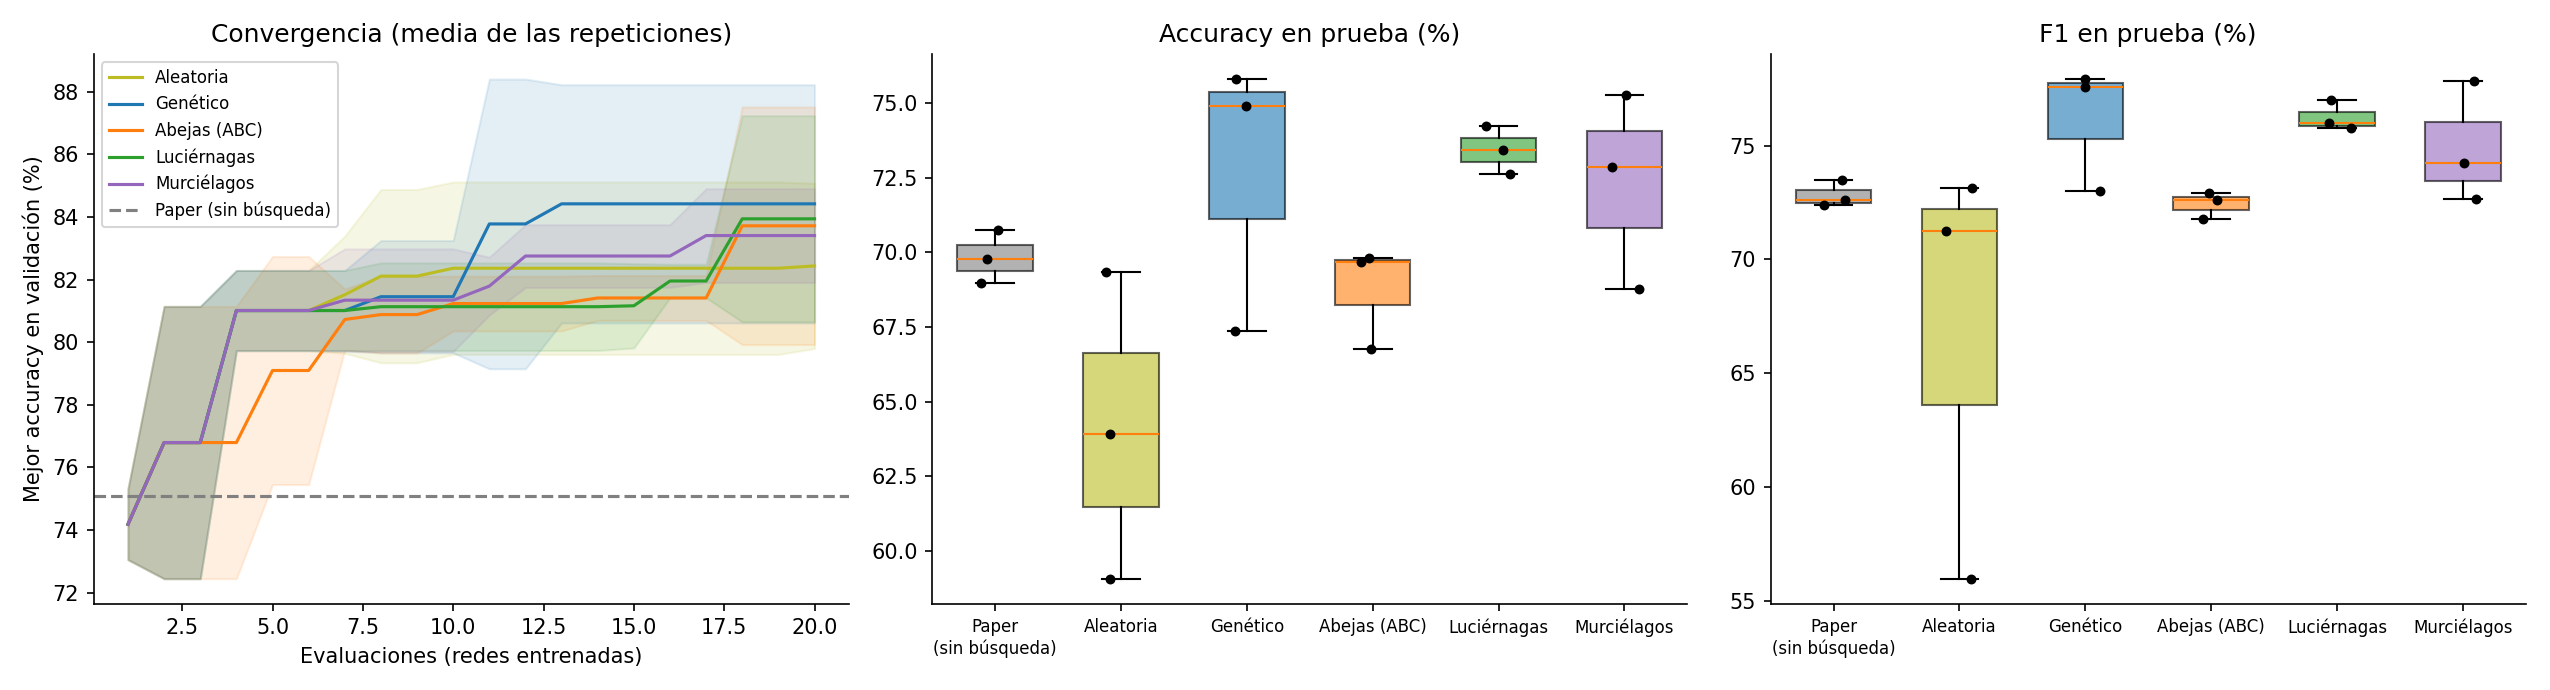

In [5]:
print("Convergencia de la aptitud (validación) y distribución de la accuracy, generadas en Colab:")
display(Image(filename=str(R / "fig_experimento1.png"), width=1100))

### 2.3 Análisis estadístico

- **ANOVA de un factor:** $Y_{ij} = \mu + \tau_i + \varepsilon_{ij}$, con $H_0$: $\tau_1 = \dots = \tau_6 = 0$ (el método de búsqueda no cambia la métrica).
- **Tukey HSD:** indica qué pares de métodos difieren.
- **t de Welch frente al control (paper):** responde directamente si cada metaheurística mejora a la configuración original.

In [6]:
for r, nombre in [("f1_test", "F1 de Drowsy"), ("recall_drowsy_test", "Sensibilidad de Drowsy")]:
    t = sm.stats.anova_lm(ols(f"{r} ~ C(algoritmo)", data=E1).fit(), typ=2)
    F, p = t.loc["C(algoritmo)", "F"], t.loc["C(algoritmo)", "PR(>F)"]
    print(f"\n=== ANOVA de un factor: {nombre} ===  F = {F:.2f}, p = {p:.4f} ->",
          "se rechaza H0" if p < 0.05 else "no se rechaza H0 (sin diferencia significativa entre los 6 métodos a la vez)")
    display(t.round(4))
    print(pairwise_tukeyhsd(E1[r], E1["algoritmo"]))


=== ANOVA de un factor: F1 de Drowsy ===  F = 2.17, p = 0.1264 -> no se rechaza H0 (sin diferencia significativa entre los 6 métodos a la vez)


,sum_sq,df,F,PR(>F)
C(algoritmo),0.0189,5.0,2.1677,0.1264
Residual,0.0209,12.0,NaN,NaN


          Multiple Comparison of Means - Tukey HSD, FWER=0.05          
   group1           group2        meandiff p-adj   lower  upper  reject
-----------------------------------------------------------------------
Abejas (ABC)            Aleatoria  -0.0564 0.5816 -0.1708  0.058  False
Abejas (ABC)             Genético   0.0374 0.8734  -0.077 0.1518  False
Abejas (ABC)          Luciérnagas   0.0382  0.863 -0.0762 0.1527  False
Abejas (ABC)          Murciélagos   0.0249 0.9741 -0.0895 0.1393  False
Abejas (ABC) Paper (sin búsqueda)    0.004    1.0 -0.1104 0.1184  False
   Aleatoria             Genético   0.0938 0.1346 -0.0207 0.2082  False
   Aleatoria          Luciérnagas   0.0946 0.1293 -0.0198 0.2091  False
   Aleatoria          Murciélagos   0.0813 0.2348 -0.0332 0.1957  False
   Aleatoria Paper (sin búsqueda)   0.0604 0.5149  -0.054 0.1748  False
    Genético          Luciérnagas   0.0009    1.0 -0.1136 0.1153  False
    Genético          Murciélagos  -0.0125 0.9989 -0.1269 0.1019

,sum_sq,df,F,PR(>F)
C(algoritmo),0.0254,5.0,0.7014,0.6331
Residual,0.0867,12.0,NaN,NaN


          Multiple Comparison of Means - Tukey HSD, FWER=0.05          
   group1           group2        meandiff p-adj   lower  upper  reject
-----------------------------------------------------------------------
Abejas (ABC)            Aleatoria  -0.0702 0.9054 -0.3034  0.163  False
Abejas (ABC)             Genético   0.0475 0.9804 -0.1857 0.2807  False
Abejas (ABC)          Luciérnagas   0.0329 0.9963 -0.2003 0.2661  False
Abejas (ABC)          Murciélagos   0.0066    1.0 -0.2266 0.2398  False
Abejas (ABC) Paper (sin búsqueda)  -0.0118    1.0  -0.245 0.2213  False
   Aleatoria             Genético   0.1177 0.5585 -0.1155 0.3509  False
   Aleatoria          Luciérnagas   0.1031 0.6789   -0.13 0.3363  False
   Aleatoria          Murciélagos   0.0768 0.8698 -0.1564   0.31  False
   Aleatoria Paper (sin búsqueda)   0.0584 0.9536 -0.1748 0.2916  False
    Genético          Luciérnagas  -0.0146 0.9999 -0.2478 0.2186  False
    Genético          Murciélagos  -0.0409 0.9898 -0.2741 0.1922

In [7]:
ctrl = E1[E1.algoritmo == ORDEN[0]]
filas = []
for a in ORDEN[1:]:
    s = E1[E1.algoritmo == a]
    fila = {"Método": a}
    for r, n in [("f1_test", "F1 Drowsy"), ("recall_drowsy_test", "Sens. Drowsy")]:
        p = stats.ttest_ind(s[r], ctrl[r], equal_var=False).pvalue
        fila[f"Δ {n} (pts)"] = round((s[r].mean() - ctrl[r].mean()) * 100, 1)
        fila[f"p {n}"] = round(p, 3)
        fila[f"¿Mejora significativa en {n}?"] = "Sí" if (p < 0.05 and s[r].mean() > ctrl[r].mean()) else "No"
    filas.append(fila)
TW = pd.DataFrame(filas).set_index("Método"); TW.to_csv(R / "tabla_welch_vs_paper.csv")
print("t de Welch: cada metaheurística frente a la configuración del paper (control)"); TW

t de Welch: cada metaheurística frente a la configuración del paper (control)


,Δ F1 Drowsy (pts),p F1 Drowsy,¿Mejora significativa en F1 Drowsy?,Δ Sens. Drowsy (pts),p Sens. Drowsy,¿Mejora significativa en Sens. Drowsy?
Método,,,,,,
Aleatoria,-6.0,0.382,No,-5.8,0.665,No
Genético,3.3,0.165,No,5.9,0.009,Sí
Abejas (ABC),-0.4,0.450,No,1.2,0.453,No
Luciérnagas,3.4,0.003,Sí,4.5,0.043,Sí
Murciélagos,2.1,0.306,No,1.8,0.540,No


### 2.4 Mejor configuración encontrada por cada método

In [8]:
cols = ["repeticion", "aptitud_val", "f1_test", "recall_drowsy_test", "tasa_aprendizaje", "neuronas_1", "neuronas_2", "dropout",
        "cuello_atencion", "weight_decay", "capas_congeladas", "lote"]
M = E1.loc[E1.groupby("algoritmo")["aptitud_val"].idxmax()].set_index("algoritmo")[cols].reindex(ORDEN)
M.style.format({"aptitud_val": "{:.3f}", "f1_test": "{:.3f}", "recall_drowsy_test": "{:.3f}", "tasa_aprendizaje": "{:.1e}", "weight_decay": "{:.1e}", "dropout": "{:.2f}"})

,repeticion,aptitud_val,f1_test,recall_drowsy_test,tasa_aprendizaje,neuronas_1,neuronas_2,dropout,cuello_atencion,weight_decay,capas_congeladas,lote
algoritmo,,,,,,,,,,,,
Paper (sin búsqueda),1,0.767,0.726,0.800,1.0e-04,512,256,0.50,32,0.0e+00,10,64
Aleatoria,2,0.850,0.560,0.520,3.3e-05,51,15,0.23,38,7.1e-03,16,32
Genético,2,0.887,0.730,0.882,1.5e-05,211,57,0.17,6,7.0e-06,14,128
Abejas (ABC),2,0.880,0.726,0.802,3.6e-04,39,16,0.10,5,2.0e-05,16,128
Luciérnagas,2,0.877,0.760,0.865,1.0e-05,218,54,0.16,6,3.9e-06,13,128
Murciélagos,2,0.847,0.778,0.868,1.2e-05,316,79,0.24,6,1.4e-06,13,128


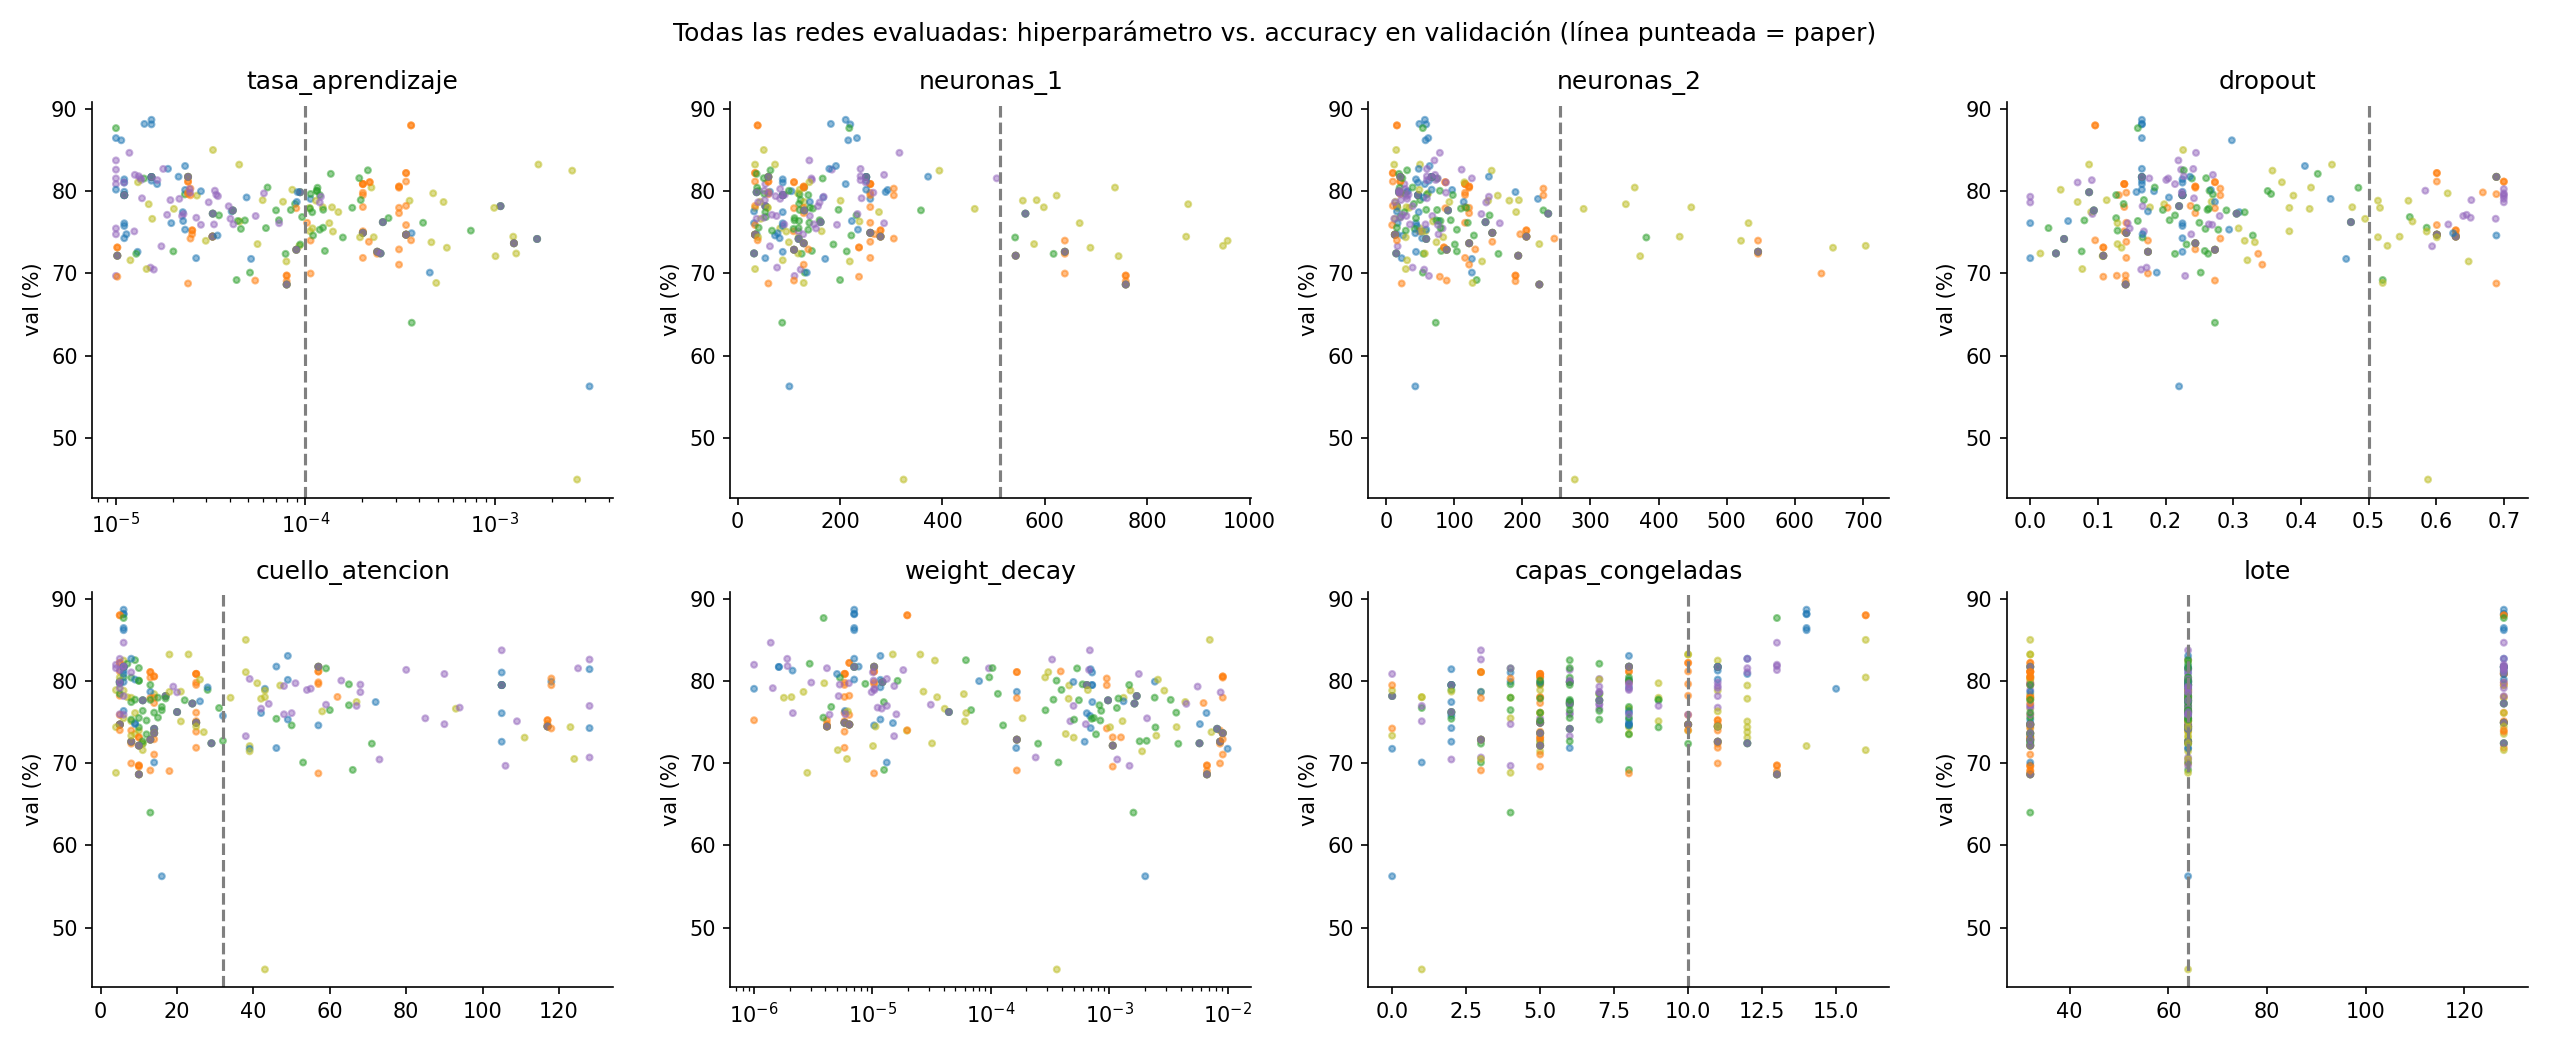

In [9]:
display(Image(filename=str(R / "fig_hiperparametros.png"), width=1100))

## 3. Resultados del experimento 2: reglas evolutivas (Michigan vs. Pittsburgh)

In [10]:
g2 = E2.groupby(["clasificador", "red"])
T2 = pd.DataFrame({"F1 Drowsy (%)": ms(g2, "f1"), "Sens. Drowsy (%)": ms(g2, "recall_drowsy"), "Sens. alerta (%)": ms(g2, "recall_alerta"),
                   "Accuracy (%)": ms(g2, "accuracy"), "Número de reglas": g2["n_reglas"].mean().round(1)})
T2.to_csv(R / "tabla_drowsy_experimento2.csv"); T2

F1 Drowsy (%) Sens. Drowsy (%)  \
clasificador        red                                                    
Michigan            Optimizada (Genético)    72.3 ± 5.6       91.4 ± 4.3   
                    Original (paper)         72.8 ± 6.2       79.7 ± 1.6   
Pittsburgh          Optimizada (Genético)    75.3 ± 2.1       89.1 ± 4.2   
                    Original (paper)         73.7 ± 0.3       83.0 ± 1.0   
Regresión logística Optimizada (Genético)    76.2 ± 2.7       86.7 ± 1.5   
                    Original (paper)         72.8 ± 0.6       80.8 ± 0.7   

                                          Sens. alerta (%) Accuracy (%)  \
clasificador        red                                                   
Michigan            Optimizada (Genético)      37.4 ± 20.8   64.4 ± 9.7   
                    Original (paper)           59.4 ± 19.8   69.6 ± 9.8   
Pittsburgh          Optimizada (Genético)       52.6 ± 1.6   70.9 ± 2.0   
                    Original (paper)            57.6 ± 2.3   70.3 ± 0.7   
Regresión logística Optimizada (Genético)      58.7 ± 10.7   72.7 ± 4.6   
                    Original (paper)            58.9 ± 2.0   69.8 ± 0.9   

                                           Número de reglas  
clasificador        red                                      
Michigan            Optimizada (Genético)             119.0  
                    Original (paper)                  120.0  
Pittsburgh          Optimizada (Genético)               2.7  
                    Original (paper)                    2.7  
Regresión logística Optimizada (Genético)               NaN  
                    Original (paper)                    NaN

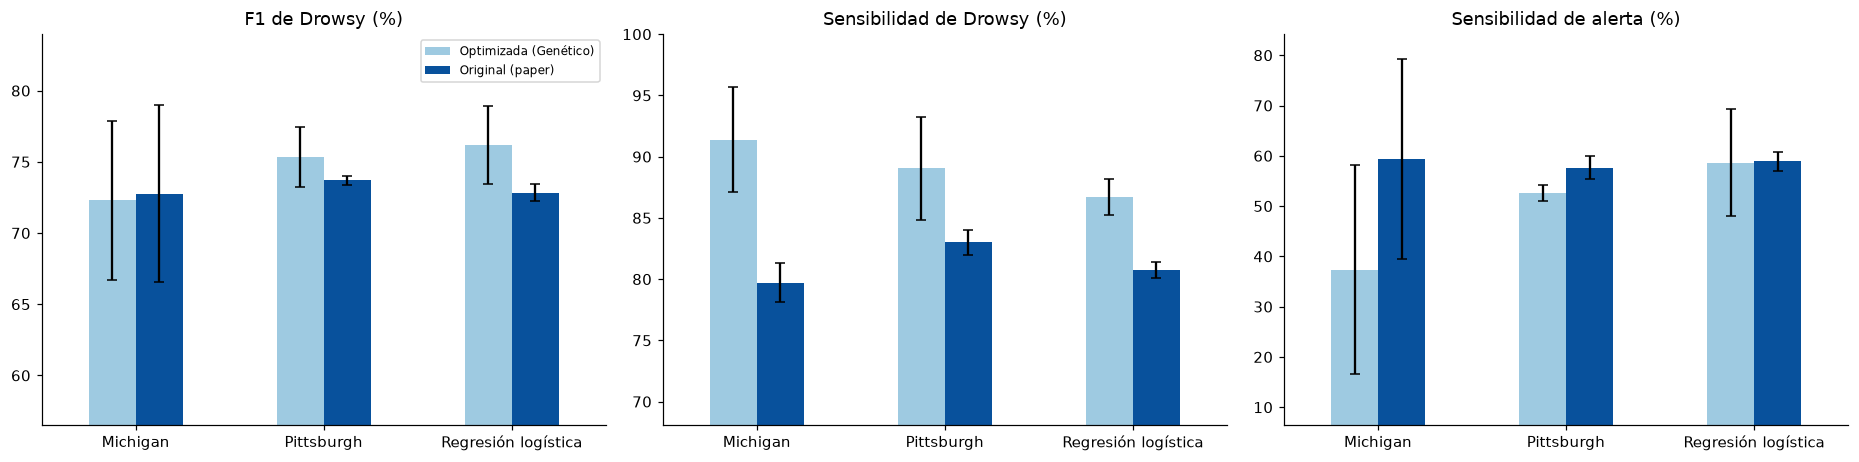


=== ANOVA de dos factores: F1 de Drowsy ===


,sum_sq,df,F,PR(>F)
C(clasificador),0.0016,2.0,0.5793,0.5752
C(red),0.0010,1.0,0.7482,0.4040
C(clasificador):C(red),0.0011,2.0,0.4006,0.6786
Residual,0.0163,12.0,NaN,NaN


  clasificador   : p = 0.5752 -> no significativo
  red de entrada : p = 0.4040 -> no significativo
  interacción    : p = 0.6786 -> no significativo

=== ANOVA de dos factores: Sensibilidad de Drowsy ===


,sum_sq,df,F,PR(>F)
C(clasificador),0.0018,2.0,1.2492,0.3215
C(red),0.0281,1.0,39.6200,0.0000
C(clasificador):C(red),0.0032,2.0,2.2803,0.1447
Residual,0.0085,12.0,NaN,NaN


  clasificador   : p = 0.3215 -> no significativo
  red de entrada : p = 0.0000 -> influye (p < 0,05)
  interacción    : p = 0.1447 -> no significativo


In [11]:
fig, ax = plt.subplots(1, 3, figsize=(17, 4.3))
for k, (m, tit) in enumerate([("f1", "F1 de Drowsy (%)"), ("recall_drowsy", "Sensibilidad de Drowsy (%)"), ("recall_alerta", "Sensibilidad de alerta (%)")]):
    piv = E2.groupby(["clasificador", "red"])[m].mean().unstack() * 100; err = E2.groupby(["clasificador", "red"])[m].std().unstack() * 100
    piv.plot.bar(yerr=err, ax=ax[k], rot=0, capsize=3, color=["#9ecae1", "#08519c"], legend=(k == 0))
    ax[k].set(title=tit, xlabel="", ylim=(max(0, (piv - err).values.min() - 10), min(100, (piv + err).values.max() + 5)))
ax[0].legend(fontsize=8)
plt.tight_layout(); plt.savefig(R / "fig_drowsy_experimento2.png", dpi=150); plt.show()
for r, nombre in [("f1", "F1 de Drowsy"), ("recall_drowsy", "Sensibilidad de Drowsy")]:
    A = sm.stats.anova_lm(ols(f"{r} ~ C(clasificador) * C(red)", data=E2).fit(), typ=2)
    print(f"\n=== ANOVA de dos factores: {nombre} ===")
    display(A.round(4))
    for f, n in [("C(clasificador)", "clasificador"), ("C(red)", "red de entrada"), ("C(clasificador):C(red)", "interacción")]:
        print(f"  {n:15s}: p = {A.loc[f, 'PR(>F)']:.4f} ->", "influye (p < 0,05)" if A.loc[f, "PR(>F)"] < 0.05 else "no significativo")

## 4. Prueba t de Student pareada: red original (paper) vs. el mejor modelo

**Pregunta:** ¿la red optimizada detecta la somnolencia mejor que la red del paper?

**Por qué es pareada:** en cada repetición, las dos redes se entrenan con **la misma semilla**, los mismos datos y las mismas personas de prueba. Lo único que cambia son los hiperparámetros, así que cada observación del modelo optimizado tiene su "gemela" en el paper. La prueba pareada analiza la **diferencia dentro de cada par**:

$$t = \frac{\bar d}{s_d / \sqrt{n}}, \qquad d_i = \text{métrica}_{\text{optimizado}, i} - \text{métrica}_{\text{paper}, i}, \qquad gl = n - 1$$

- $H_0$: $\mu_d = 0$ (no hay diferencia).
- $H_a$: $\mu_d > 0$ (el optimizado es mejor). Es una prueba de una cola, con $\alpha = 0{,}05$.

**Mejor modelo:**
- **Genético:** es el elegido por validación, sin mirar la prueba. Es la comparación honesta.
- **Luciérnagas:** obtuvo el mejor F1 de Drowsy en prueba. Se muestra como referencia.

**Dos formas de emparejar:**
1. **Por repetición** (n = 3 pares): la métrica global de cada corrida.
2. **Por persona × repetición** (n = 5 personas de prueba × 3 repeticiones = 15 pares): la métrica de cada persona. Tiene más potencia estadística. Se calcula a partir de los cierres guardados en la caché de Colab, aplicando la misma calibración y la misma regresión logística.

In [12]:
COMP = ["Genético", "Luciérnagas"]
def pareada(a, b):
    d = np.asarray(a) - np.asarray(b)
    t, p2 = stats.ttest_rel(a, b)
    p1 = p2 / 2 if t > 0 else 1 - p2 / 2
    ic = stats.t.interval(0.95, len(d) - 1, loc=d.mean(), scale=stats.sem(d)) if len(d) > 1 else (np.nan, np.nan)
    return {"n pares": len(d), "media paper (%)": round(np.mean(b) * 100, 1), "media optimizado (%)": round(np.mean(a) * 100, 1),
            "diferencia media (pts)": round(d.mean() * 100, 2), "IC 95 % (pts)": f"[{ic[0] * 100:.2f}, {ic[1] * 100:.2f}]",
            "t": round(t, 3), "gl": len(d) - 1, "p (una cola)": round(p1, 4), "¿Significativo (α = 0,05)?": "Sí" if p1 < 0.05 else "No"}

filas = []
P = E1[E1.algoritmo == ORDEN[0]].sort_values("repeticion")
for a in COMP:
    A = E1[E1.algoritmo == a].sort_values("repeticion")
    for r, n in [("f1_test", "F1 Drowsy"), ("recall_drowsy_test", "Sens. Drowsy"), ("accuracy_test", "Accuracy")]:
        filas.append({"Comparación": f"{a} vs. Paper", "Métrica": n, **pareada(A[r].values, P[r].values)})
TP1 = pd.DataFrame(filas).set_index(["Comparación", "Métrica"]); TP1.to_csv(R / "t_pareada_por_repeticion.csv")
print("Prueba t pareada emparejando por REPETICIÓN (misma semilla):"); TP1

Prueba t pareada emparejando por REPETICIÓN (misma semilla):


n pares  media paper (%)  \
Comparación           Métrica                                  
Genético vs. Paper    F1 Drowsy           3             72.8   
                      Sens. Drowsy        3             80.8   
                      Accuracy            3             69.8   
Luciérnagas vs. Paper F1 Drowsy           3             72.8   
                      Sens. Drowsy        3             80.8   
                      Accuracy            3             69.8   

                                    media optimizado (%)  \
Comparación           Métrica                              
Genético vs. Paper    F1 Drowsy                     76.2   
                      Sens. Drowsy                  86.7   
                      Accuracy                      72.7   
Luciérnagas vs. Paper F1 Drowsy                     76.3   
                      Sens. Drowsy                  85.2   
                      Accuracy                      73.4   

                                    diferencia media (pts)    IC 95 % (pts)  \
Comparación           Métrica                                                 
Genético vs. Paper    F1 Drowsy                       3.34   [-4.87, 11.54]   
                      Sens. Drowsy                    5.94     [3.25, 8.62]   
                      Accuracy                        2.86  [-10.57, 16.30]   
Luciérnagas vs. Paper F1 Drowsy                       3.42     [1.08, 5.76]   
                      Sens. Drowsy                    4.48   [-1.36, 10.31]   
                      Accuracy                        3.59    [-0.09, 7.27]   

                                        t  gl  p (una cola)  \
Comparación           Métrica                                 
Genético vs. Paper    F1 Drowsy     1.749   2        0.1112   
                      Sens. Drowsy  9.526   2        0.0054   
                      Accuracy      0.917   2        0.2279   
Luciérnagas vs. Paper F1 Drowsy     6.293   2        0.0122   
                      Sens. Drowsy  3.300   2        0.0404   
                      Accuracy      4.203   2        0.0261   

                                   ¿Significativo (α = 0,05)?  
Comparación           Métrica                                  
Genético vs. Paper    F1 Drowsy                            No  
                      Sens. Drowsy                         Sí  
                      Accuracy                             No  
Luciérnagas vs. Paper F1 Drowsy                            Sí  
                      Sens. Drowsy                         Sí  
                      Accuracy                             Sí

In [13]:
# Métricas por persona de prueba, a partir de los cierres guardados en la caché de Colab
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import f1_score, recall_score
import sys
F_PERSONA = R / "metricas_por_persona.csv"
CACHE = R.parent if R.parent.name == "SomnIA_colab" else Path.home() / "Library/CloudStorage/GoogleDrive-lopezdanielh.566@gmail.com/Mi unidad/SomnIA_colab"
if not F_PERSONA.exists():
    sys.path.insert(0, str(R.parent)); import somnia_meta as smeta
    meta = pd.read_csv(CACHE / "meta_ojos.csv")
    Dc = smeta.Datos(np.zeros((len(meta), 2, 1), np.float32), meta, paso_train=1)
    filas = []
    for fila in E1[E1.algoritmo.isin([ORDEN[0]] + COMP)].itertuples():
        z = np.load(CACHE / "cache" / f"{fila.clave}.npz")
        Ftr, ok = smeta.calibrar(Dc, Dc.idx["train"], z["train"]); ytr = Dc.label[Dc.idx["train"]]
        clf = make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000, class_weight="balanced")).fit(Ftr[ok], ytr[ok])
        Fte, okt = smeta.calibrar(Dc, Dc.idx["test"], z["test"])
        te = meta.loc[Dc.idx["test"][okt]].assign(pred=clf.predict(Fte[okt]))
        for persona, g in te.groupby("person"):
            filas.append({"algoritmo": fila.algoritmo, "repeticion": fila.repeticion, "persona": persona, "fotogramas": len(g),
                          "f1": f1_score(g.label, g.pred), "recall_drowsy": recall_score(g.label, g.pred),
                          "recall_alerta": recall_score(g.label, g.pred, pos_label=0), "accuracy": (g.label == g.pred).mean()})
    pd.DataFrame(filas).to_csv(F_PERSONA, index=False)
PP = pd.read_csv(F_PERSONA)
print("Métricas por persona de prueba (media de las 3 repeticiones):")
PP.groupby(["persona", "algoritmo"])[["f1", "recall_drowsy", "recall_alerta"]].mean().unstack().mul(100).round(1)

Métricas por persona de prueba (media de las 3 repeticiones):


f1                                  recall_drowsy              \
algoritmo Genético Luciérnagas Paper (sin búsqueda)      Genético Luciérnagas   
persona                                                                         
P05           59.2        59.6                 56.6          90.6        92.4   
P07           84.3        84.9                 83.2          89.0        84.2   
P15           62.2        60.0                 35.1          52.4        51.2   
P18           83.7        84.3                 89.1          99.9       100.0   
P20           97.2        97.1                 96.4          99.9        98.6   

                               recall_alerta                                   
algoritmo Paper (sin búsqueda)      Genético Luciérnagas Paper (sin búsqueda)  
persona                                                                        
P05                       96.6          40.3        41.1                 27.7  
P07                       81.2          72.8        82.2                 82.7  
P15                       24.3          82.2        81.1                 83.1  
P18                       99.9          21.4        24.3                 50.7  
P20                       99.9          93.7        94.9                 91.9

In [14]:
filas = []
for a in COMP:
    m = PP[PP.algoritmo == a].merge(PP[PP.algoritmo == ORDEN[0]], on=["repeticion", "persona"], suffixes=("_opt", "_paper"))
    for r, n in [("f1", "F1 Drowsy"), ("recall_drowsy", "Sens. Drowsy"), ("accuracy", "Accuracy")]:
        filas.append({"Comparación": f"{a} vs. Paper", "Métrica": n, **pareada(m[f"{r}_opt"].values, m[f"{r}_paper"].values),
                      "pares en que mejora": f"{(m[f'{r}_opt'] > m[f'{r}_paper']).sum()} de {len(m)}",
                      "p Wilcoxon (una cola)": round(stats.wilcoxon(m[f"{r}_opt"], m[f"{r}_paper"], alternative="greater").pvalue, 4)})
TP2 = pd.DataFrame(filas).set_index(["Comparación", "Métrica"]); TP2.to_csv(R / "t_pareada_por_persona.csv")
print("Prueba t pareada emparejando por PERSONA × REPETICIÓN (15 pares); Wilcoxon como prueba no paramétrica de respaldo:"); TP2

Prueba t pareada emparejando por PERSONA × REPETICIÓN (15 pares); Wilcoxon como prueba no paramétrica de respaldo:


n pares  media paper (%)  \
Comparación           Métrica                                  
Genético vs. Paper    F1 Drowsy          15             72.1   
                      Sens. Drowsy       15             80.4   
                      Accuracy           15             72.6   
Luciérnagas vs. Paper F1 Drowsy          15             72.1   
                      Sens. Drowsy       15             80.4   
                      Accuracy           15             72.6   

                                    media optimizado (%)  \
Comparación           Métrica                              
Genético vs. Paper    F1 Drowsy                     77.3   
                      Sens. Drowsy                  86.3   
                      Accuracy                      75.1   
Luciérnagas vs. Paper F1 Drowsy                     77.2   
                      Sens. Drowsy                  85.3   
                      Accuracy                      75.6   

                                    diferencia media (pts)   IC 95 % (pts)  \
Comparación           Métrica                                                
Genético vs. Paper    F1 Drowsy                       5.22  [-1.69, 12.14]   
                      Sens. Drowsy                    5.97  [-1.18, 13.13]   
                      Accuracy                        2.49   [-3.63, 8.62]   
Luciérnagas vs. Paper F1 Drowsy                       5.07  [-1.94, 12.08]   
                      Sens. Drowsy                    4.91  [-2.91, 12.72]   
                      Accuracy                        2.99   [-2.40, 8.37]   

                                        t  gl  p (una cola)  \
Comparación           Métrica                                 
Genético vs. Paper    F1 Drowsy     1.620  14        0.0638   
                      Sens. Drowsy  1.790  14        0.0476   
                      Accuracy      0.873  14        0.1986   
Luciérnagas vs. Paper F1 Drowsy     1.550  14        0.0717   
                      Sens. Drowsy  1.347  14        0.0997   
                      Accuracy      1.189  14        0.1271   

                                   ¿Significativo (α = 0,05)?  \
Comparación           Métrica                                   
Genético vs. Paper    F1 Drowsy                            No   
                      Sens. Drowsy                         Sí   
                      Accuracy                             No   
Luciérnagas vs. Paper F1 Drowsy                            No   
                      Sens. Drowsy                         No   
                      Accuracy                             No   

                                   pares en que mejora  p Wilcoxon (una cola)  
Comparación           Métrica                                                  
Genético vs. Paper    F1 Drowsy               10 de 15                 0.1262  
                      Sens. Drowsy             8 de 15                 0.0790  
                      Accuracy                10 de 15                 0.1947  
Luciérnagas vs. Paper F1 Drowsy               11 de 15                 0.0844  
                      Sens. Drowsy             9 de 15                 0.0790  
                      Accuracy                10 de 15                 0.1384

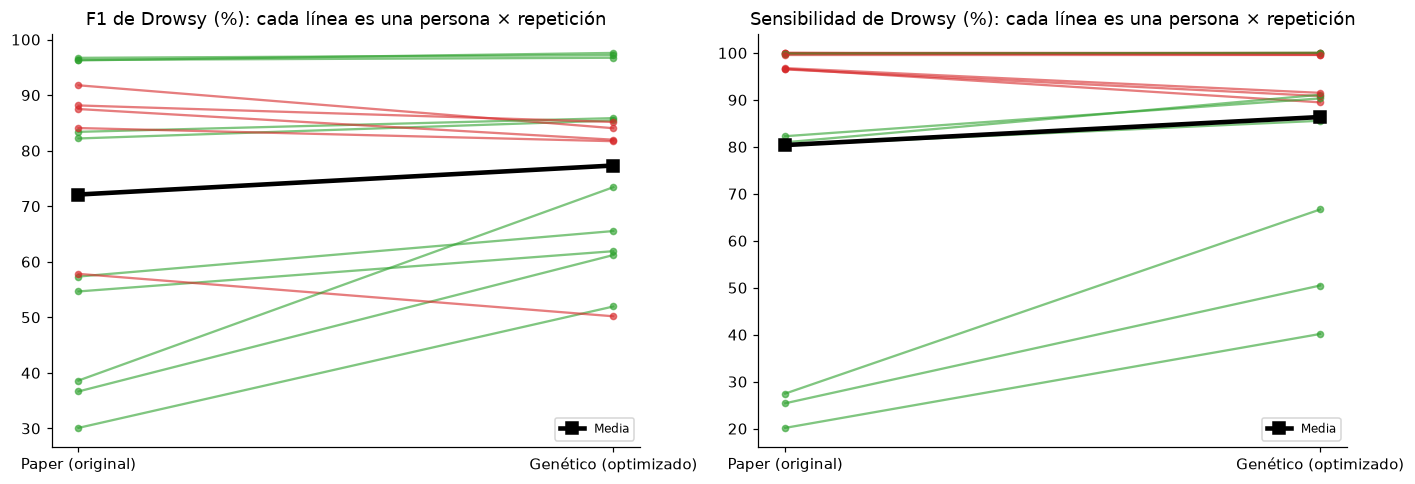

In [15]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
for k, (r, tit) in enumerate([("f1", "F1 de Drowsy (%)"), ("recall_drowsy", "Sensibilidad de Drowsy (%)")]):
    m = PP[PP.algoritmo == "Genético"].merge(PP[PP.algoritmo == ORDEN[0]], on=["repeticion", "persona"], suffixes=("_opt", "_paper"))
    for _, f in m.iterrows():
        c = "#2ca02c" if f[f"{r}_opt"] > f[f"{r}_paper"] else "#d62728"
        ax[k].plot([0, 1], [f[f"{r}_paper"] * 100, f[f"{r}_opt"] * 100], "-o", color=c, alpha=0.6, ms=4)
    ax[k].plot([0, 1], [m[f"{r}_paper"].mean() * 100, m[f"{r}_opt"].mean() * 100], "-s", color="k", lw=3, ms=8, label="Media")
    ax[k].set_xticks([0, 1], ["Paper (original)", "Genético (optimizado)"]); ax[k].set_title(tit + ": cada línea es una persona × repetición")
    ax[k].legend(fontsize=8)
plt.tight_layout(); plt.savefig(R / "fig_t_pareada.png", dpi=150); plt.show()

**Cómo leer las tablas:**
- **Por repetición (n = 3):** con solo 2 grados de libertad la prueba tiene muy poca potencia. Solo detecta diferencias muy grandes y muy consistentes.
- **Por persona × repetición (n = 15):** mide si la mejora se repite **en la mayoría de las personas**. Es la prueba más informativa para el documento. La prueba de Wilcoxon confirma el resultado sin suponer normalidad.
- **La comparación honesta es Genético vs. Paper,** porque el Genético se eligió por validación. Luciérnagas se eligió mirando la prueba, así que su resultado es optimista.

## 5. Comparaciones y conclusiones

**Experimento 1 (metaheurísticas):**
- **Luciérnagas** y el **algoritmo genético** son los mejores métodos.
  - **F1 de Drowsy:** suben de 72,8 % (paper) a **76,3 %** y **76,2 %**.
  - **Sensibilidad de Drowsy:** sube de 80,8 % a **85,2 %** y **86,7 %**. El modelo deja de detectar menos conductores somnolientos.
- **Contra el paper (t de Welch):** la mejora es significativa para **Luciérnagas** en F1 (p = 0,003) y en sensibilidad (p = 0,043), y para el **Genético** en sensibilidad (p = 0,009).
- **Murciélagos** mejora un poco sin ser significativo, y **Abejas (ABC)** queda al nivel del paper.
- **La búsqueda aleatoria es la peor y la más inestable:** en una repetición su sensibilidad de Drowsy cayó a 52 %.
- **ANOVA conjunto de los 6 métodos:** no alcanza significancia (F1 p = 0,13; sensibilidad p = 0,63). Con solo 3 repeticiones, la enorme varianza de la búsqueda aleatoria domina la prueba.
- **Lo que tienen en común las mejores configuraciones:**
  - tasa de aprendizaje baja (~1e-5);
  - más convoluciones congeladas (13 a 14, frente a 10);
  - un cuello de atención muy pequeño (6 neuronas, frente a 32);
  - lote de 128.

**Experimento 2 (reglas evolutivas):**
- **Usar la red optimizada sube de forma significativa la sensibilidad de Drowsy** (factor red, p < 0,001).
- El tipo de clasificador no cambia el F1 de forma significativa.
- **Michigan** detecta el 91 % de los somnolientos, pero dispara las falsas alarmas: la sensibilidad de alerta baja a 37 %.
- **Pittsburgh** mantiene un buen balance (F1 75,3 %) con solo **~3 reglas legibles**. Es el clasificador más interpretable.

**Limitaciones:**
- La aptitud fue la accuracy en validación y no el F1 de Drowsy.
- Se usaron 3 repeticiones y un solo pliegue por persona.
- La validación con 5 personas favorece configuraciones que solo funcionan para esas personas: la búsqueda aleatoria logra 82 % en validación pero 64 % en prueba.

[1] O. F. Hassan *et al.*, "Real-time driver drowsiness detection using transformer architectures: a novel deep learning approach," *Sci. Rep.*, vol. 15, art. 17493, 2025.